## Section 1: Introduction

This notebook explores the IBM Telco Customer Churn dataset to understand customer characteristics, identify factors associated with churn, and guide subsequent preprocessing and model development.

In [1]:
import sys
from pathlib import Path
print(Path.cwd())

c:\Users\Deputy\customer-churn-prediction\notebooks


In [5]:
#Add project root to python path
PROJECT_ROOT = Path().resolve().parents[0]
sys.path.append(str(PROJECT_ROOT))

print("Project root added", PROJECT_ROOT)

Project root added C:\Users\Deputy\customer-churn-prediction


In [6]:
# load data
from src.data_loader import load_data

df = load_data()

## Section 2: Dataset Summary

In [7]:
df.info()

df.describe()

df.describe(include="object")

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

C:\Users\Deputy\AppData\Local\Temp\ipykernel_20748\3133019324.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,CustomerID,Country,State,City,Lat Long,Gender,Senior Citizen,Partner,Dependents,Phone Service,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Total Charges,Churn Label,Churn Reason
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043,7043,1869
unique,7043,1,1,1129,1652,2,2,2,2,2,...,3,3,3,3,3,2,4,6531,2,20
top,3668-QPYBK,United States,California,Los Angeles,"33.964131, -118.272783",Male,No,No,No,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No,Attitude of support person
freq,1,7043,7043,305,5,3555,5901,3641,5416,6361,...,3095,3473,2810,2785,3875,4171,2365,11,5174,192


## Section 3: Target Variable Analysis

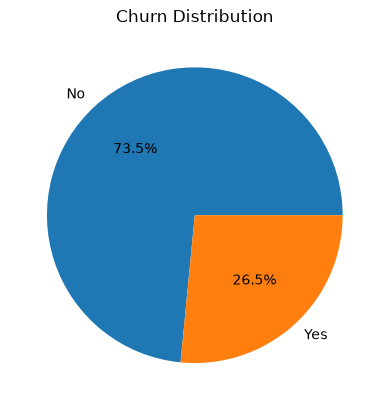

In [21]:
#Pie Chart of Churn Distribution
import matplotlib.pyplot as plt

churn_counts = df['Churn Label'].value_counts()
plt.pie(churn_counts.values, labels=churn_counts.index, autopct='%1.1f%%')
plt.title('Churn Distribution')
plt.show()

**Business Interpretation**
The pie chart shows that churn is a minority class in this dataset, with about 26.5% of customers labeled as churned and 73.5% as retained. This indicates a moderate class imbalance, so modeling should account for that imbalance rather than treating the classes as equally represented. Stratified sampling should be used during model training.

## Section 4: Numerical Variables

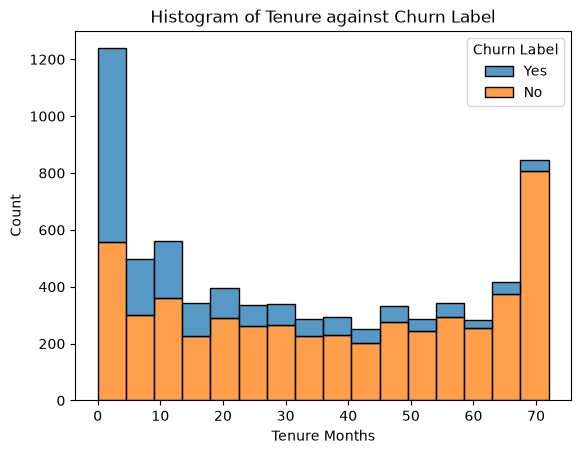

In [31]:
#Histogram of Tenure Months against Churn Label
import seaborn as sns

sns.histplot(data=df, x='Tenure Months', hue='Churn Label', multiple='stack')
plt.title('Histogram of Tenure against Churn Label')
plt.xlabel('Tenure Months')
plt.ylabel('Count')
plt.show()


**Business Interpretation**
This histogram shows that customers with shorter tenures are much more likely to churn. The churned group is concentrated in the early months of the relationship, while retained customers are spread across a wider range of tenure values. This suggests that early-life customer experience is a strong churn risk factor.

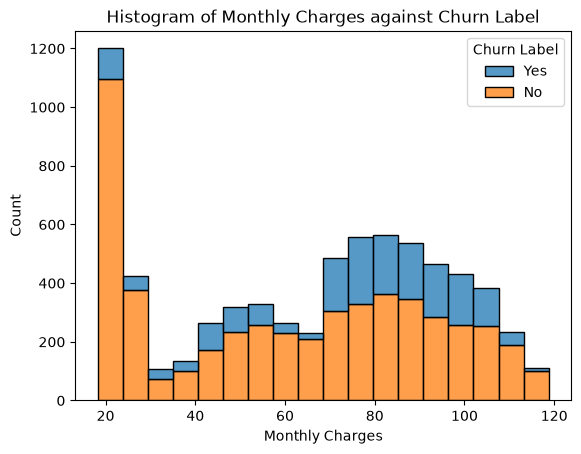

In [32]:
# Histogram of Monthly Charges against Churn Label
sns.histplot(data=df, x='Monthly Charges', hue='Churn Label', multiple='stack')
plt.title('Histogram of Monthly Charges against Churn Label')
plt.xlabel('Monthly Charges')
plt.ylabel('Count')
plt.show()
    

**Business Interpretation**
The monthly charges histogram indicates that customers with higher monthly bills are more likely to churn. The churned group is skewed toward the upper end of the monthly charges range, while the retained group includes more customers in the lower-to-middle range. This points to pricing or value perceptions as potential drivers of churn.

c:\Users\Deputy\customer-churn-prediction\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


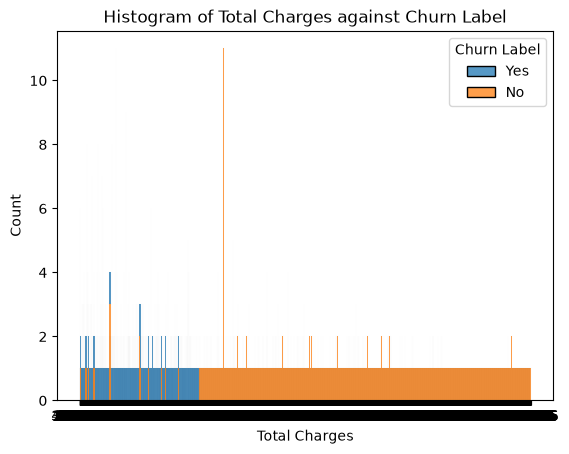

In [27]:
# Histogram of Total Charges against Churn Label
sns.histplot(data=df, x='Total Charges', hue='Churn Label', multiple='stack')
plt.title('Histogram of Total Charges against Churn Label')
plt.xlabel('Total Charges')
plt.ylabel('Count')
plt.show()


**Business Interpretation**
This total charges plot suggests that customers with lower cumulative spending are more likely to churn, especially in the lower range of total charges. The retained group appears more concentrated in higher total-charge values, which may reflect longer-term engagement and stronger customer lifetime value. This makes total charges a useful signal for identifying at-risk customers.

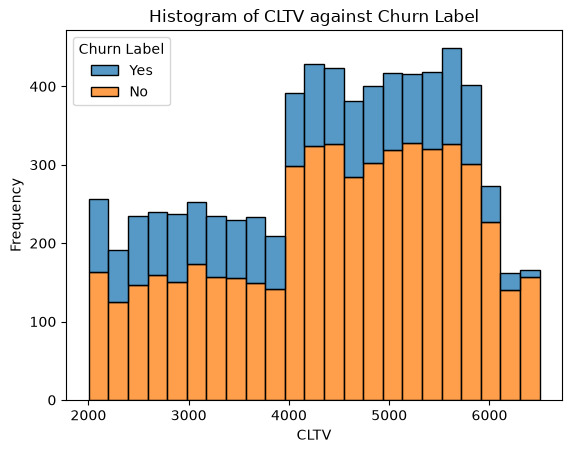

In [28]:
# Histogram of CLTV against Churn Label
sns.histplot(data=df, x='CLTV', hue='Churn Label', multiple='stack')
plt.title('Histogram of CLTV against Churn Label')
plt.xlabel('CLTV')
plt.ylabel('Frequency')
plt.show()

**Business Interpretation**
The CLTV histogram shows that churned customers tend to have somewhat lower customer lifetime value than retained customers. The retained group is shifted toward higher CLTV values, which aligns with the idea that long-term, more valuable customers are less likely to leave. This reinforces the importance of customer value as a churn-related factor.

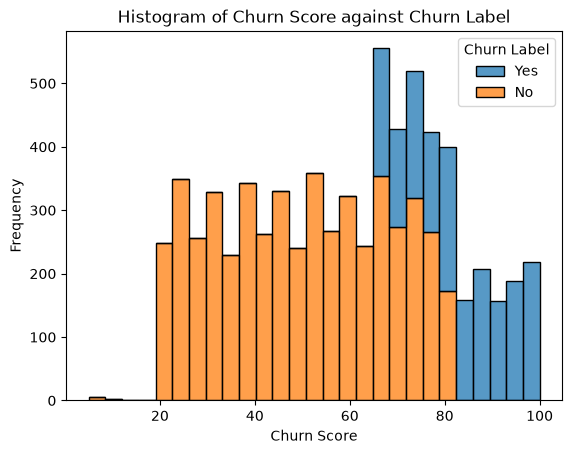

In [29]:
# Histogram of Churn Score against Churn Label
sns.histplot(data=df, x='Churn Score', hue='Churn Label', multiple='stack')
plt.title('Histogram of Churn Score against Churn Label')
plt.xlabel('Churn Score')
plt.ylabel('Frequency')
plt.show()

**Business Interpretation**
The churn score histogram shows a clear separation between the two groups: churned customers are concentrated in much higher churn-score ranges, while retained customers are more common in the lower and middle ranges. This indicates that the churn score is a strong predictor of customer exit risk and should be treated as an important feature in later modeling steps.

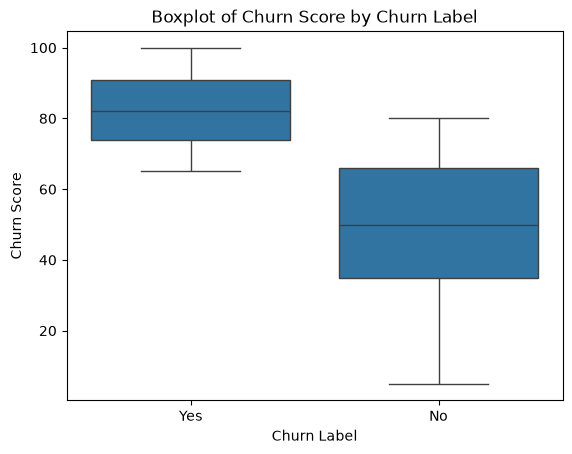

In [30]:
# Boxplot of churn score by churn label
sns.boxplot(data=df, x='Churn Label', y='Churn Score')
plt.title('Boxplot of Churn Score by Churn Label')
plt.xlabel('Churn Label')
plt.ylabel('Churn Score')
plt.show()

**Business Interpretation**
The boxplot reinforces the same message: churned customers have a substantially higher median churn score than retained customers, and the distribution for churned customers sits well above that of the retained group. This makes churn score one of the clearest signals in the notebook for identifying likely churners.

## Section 5: Categorical Variables

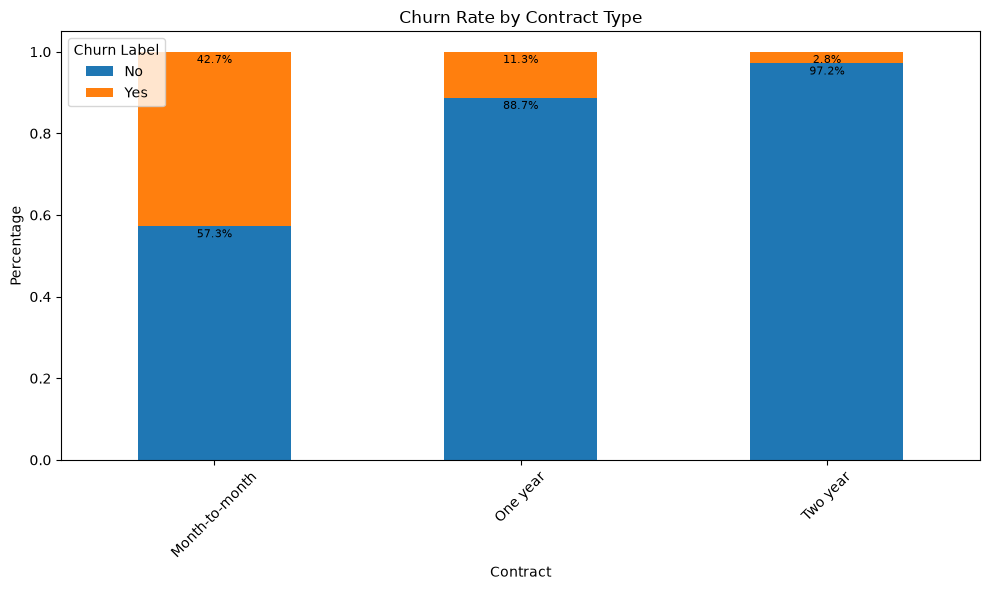

In [47]:
#Multiple Percentage Bar Chart of Churn Label by Contract Type
import matplotlib.pyplot as plt

contract_churn_counts = df.groupby(['Contract', 'Churn Label']).size().unstack(fill_value=0)
contract_churn_percentage = contract_churn_counts.div(contract_churn_counts.sum(axis=1), axis=0)

ax = contract_churn_percentage.plot(kind='bar', stacked=True, figsize=(10, 6))
for container in ax.containers:
    labels = [f'{(value * 100):.1f}%' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=-10, fontsize=8)

ax.set_title('Churn Rate by Contract Type')
ax.set_xlabel('Contract')
ax.set_ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Interpretation**
Customers on month-to-month contracts show the highest churn rate at about 42.7%, compared with 11.3% for one-year contracts and only 2.8% for two-year contracts. This suggests that customers who are not locked into longer commitments are much more likely to leave, making contract length a strong retention lever.

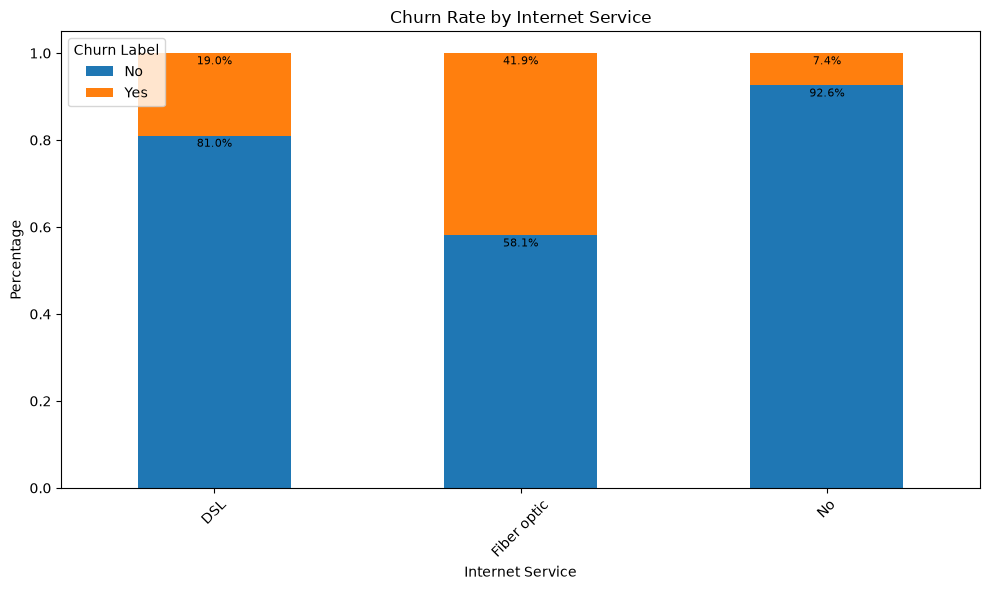

In [56]:
# Stacked percentage Bar Chart of Churn by Internet services with data label
internet_service_churn_counts = df.groupby(['Internet Service', 'Churn Label']).size().unstack(fill_value=0)
internet_service_churn_percentage = internet_service_churn_counts.div(internet_service_churn_counts.sum(axis=1), axis=0)

ax = internet_service_churn_percentage.plot(kind='bar', stacked=True, figsize=(10, 6))
for container in ax.containers:
    labels = [f'{(value * 100):.1f}%' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=-10, fontsize=8)

ax.set_title('Churn Rate by Internet Service')
ax.set_xlabel('Internet Service')
ax.set_ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Interpretation**
Fiber optic users have the highest churn rate at about 41.9%, compared with 19.0% for DSL users and 7.4% for customers without internet service. This suggests that customers with more demanding or premium internet services may be more sensitive to service quality and pricing.

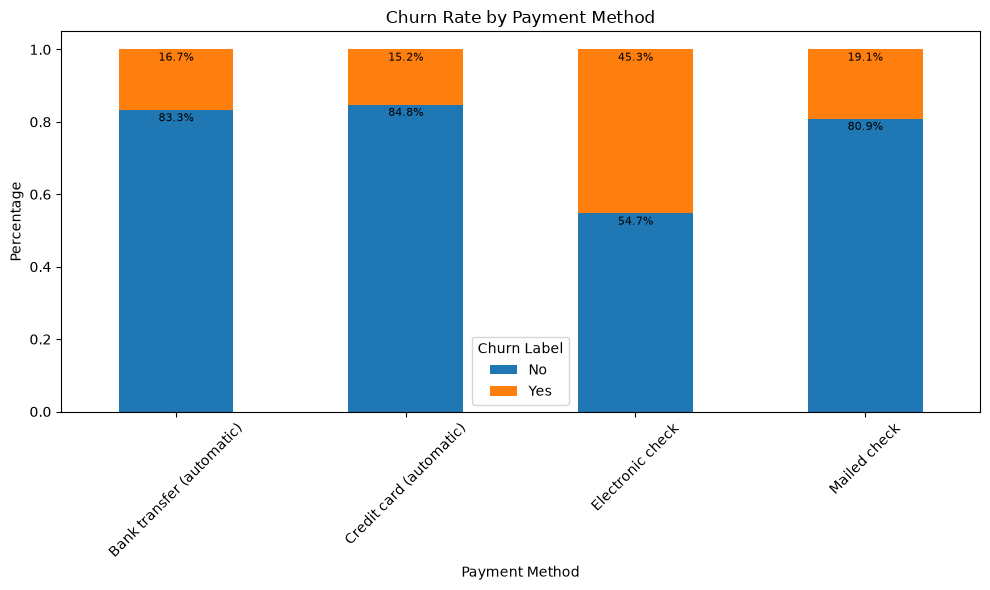

In [57]:
#Stacked Percentage Bar Chart of churn label by Payment Method
payment_method_churn_counts = df.groupby(['Payment Method', 'Churn Label']).size().unstack(fill_value=0)
payment_method_churn_percentage = payment_method_churn_counts.div(payment_method_churn_counts.sum(axis=1), axis=0)

ax = payment_method_churn_percentage.plot(kind='bar', stacked=True, figsize=(10, 6))
for container in ax.containers:
    labels = [f'{(value * 100):.1f}%' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=-10, fontsize=8)

ax.set_title('Churn Rate by Payment Method')
ax.set_xlabel('Payment Method')
ax.set_ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Interpretation**
Customers paying by electronic check have the highest churn rate at about 45.3%, compared with 19.1% for mailed check, 16.7% for bank transfer, and 15.2% for credit card payments. This points to payment experience and convenience as possible retention issues.

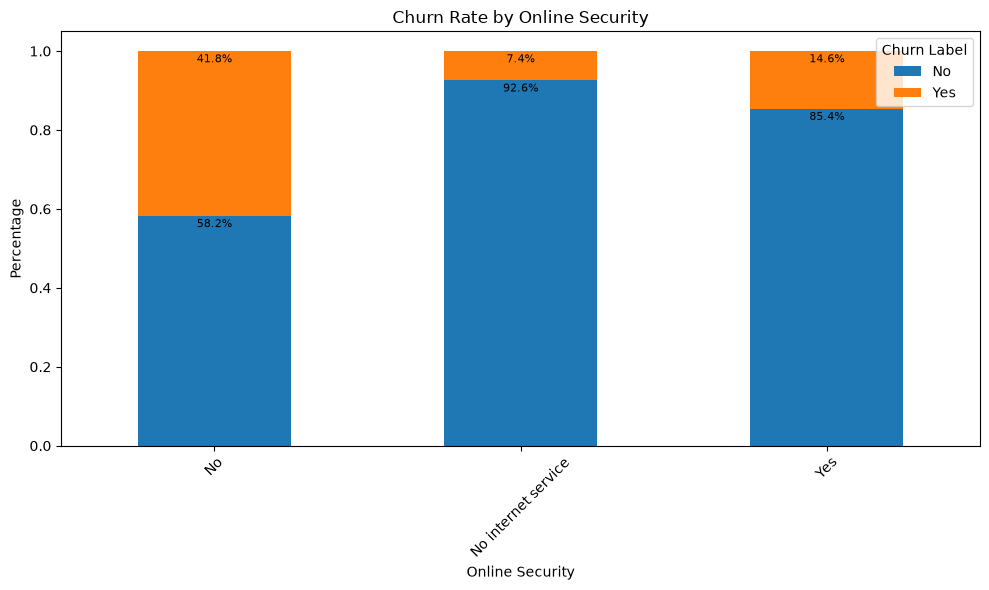

In [58]:
# Stacked percentage bar chart of churn label by Online Security
online_security_churn_counts = df.groupby(['Online Security', 'Churn Label']).size().unstack(fill_value=0)
online_security_churn_percentage = online_security_churn_counts.div(online_security_churn_counts.sum(axis=1), axis=0)

ax = online_security_churn_percentage.plot(kind='bar', stacked=True, figsize=(10, 6))
for container in ax.containers:
    labels = [f'{(value * 100):.1f}%' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=-10, fontsize=8)

ax.set_title('Churn Rate by Online Security')
ax.set_xlabel('Online Security')
ax.set_ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Interpretation**
Customers without online security have a much higher churn rate at about 41.8%, compared with 14.6% for those with online security and 7.4% for customers with no internet service. This highlights online security as an important trust and service-value factor for retention.

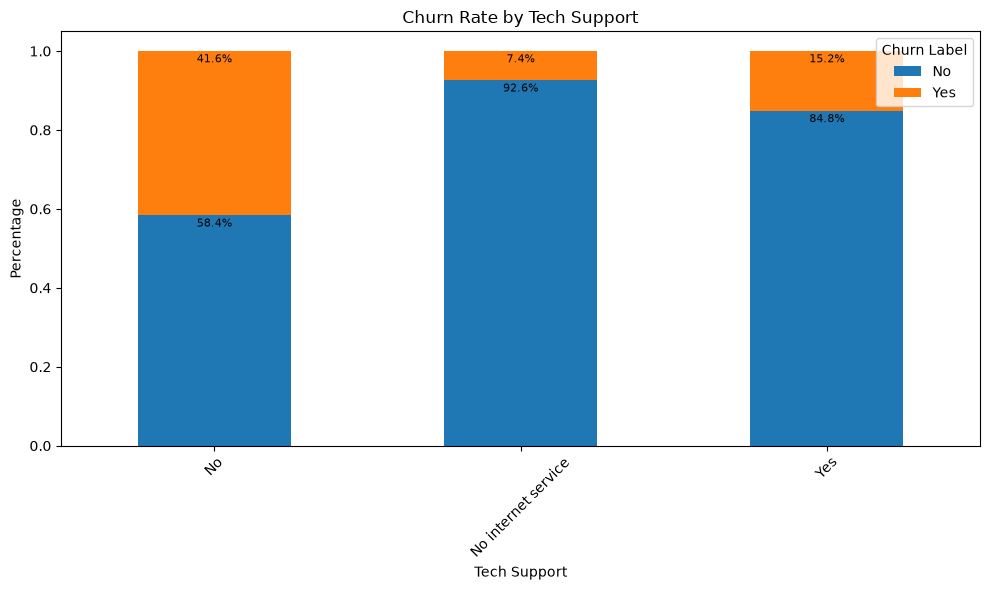

In [52]:
# Stacked percentage bar chart of churn label by Tech Support

tech_support_churn_counts = df.groupby(['Tech Support', 'Churn Label']).size().unstack(fill_value=0)
tech_support_churn_percentage = tech_support_churn_counts.div(tech_support_churn_counts.sum(axis=1), axis=0)

ax = tech_support_churn_percentage.plot(kind='bar', stacked=True, figsize=(10, 6))
for container in ax.containers:
    labels = [f'{(value * 100):.1f}%' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=-10, fontsize=8)

ax.set_title('Churn Rate by Tech Support')
ax.set_xlabel('Tech Support')
ax.set_ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Interpretation**
Customers without tech support show a churn rate of about 41.6%, compared with 15.2% for those who have it and 7.4% for customers without internet service. This suggests that accessible support is a meaningful part of customer retention.

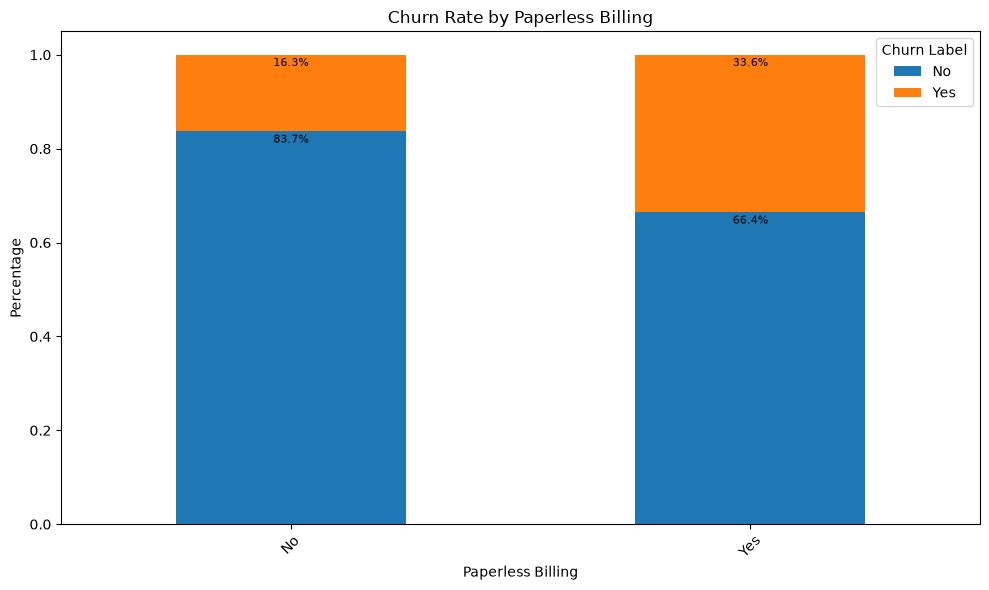

In [53]:
# Stacked percentage bar chart of churn label by Paperless Billing

paperless_billing_churn_counts = df.groupby(['Paperless Billing', 'Churn Label']).size().unstack(fill_value=0)
paperless_billing_churn_percentage = paperless_billing_churn_counts.div(paperless_billing_churn_counts.sum(axis=1), axis=0)

ax = paperless_billing_churn_percentage.plot(kind='bar', stacked=True, figsize=(10, 6))
for container in ax.containers:
    labels = [f'{(value * 100):.1f}%' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=-10, fontsize=8)

ax.set_title('Churn Rate by Paperless Billing')
ax.set_xlabel('Paperless Billing')
ax.set_ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Interpretation**
Customers using paperless billing show a churn rate of about 33.6%, compared with 16.3% for those who do not. This indicates that billing preference may be associated with broader engagement patterns and could be a useful segmenting signal.

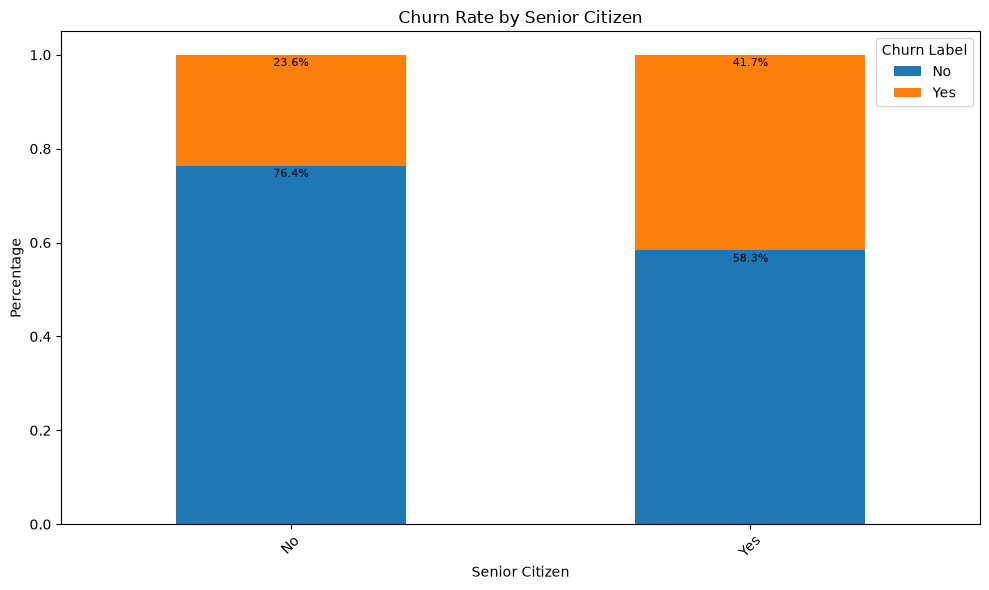

In [54]:
# Stacked percentage bar chart of churn label by Senior Citizen

senior_citizen_churn_counts = df.groupby(['Senior Citizen', 'Churn Label']).size().unstack(fill_value=0)
senior_citizen_churn_percentage = senior_citizen_churn_counts.div(senior_citizen_churn_counts.sum(axis=1), axis=0)

ax = senior_citizen_churn_percentage.plot(kind='bar', stacked=True, figsize=(10, 6))
for container in ax.containers:
    labels = [f'{(value * 100):.1f}%' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=-10, fontsize=8)

ax.set_title('Churn Rate by Senior Citizen')
ax.set_xlabel('Senior Citizen')
ax.set_ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Interpretation**
Senior citizens show a higher churn rate at about 41.7%, compared with 23.6% for non-senior customers. This suggests that older customers may require different engagement or support strategies to reduce attrition.

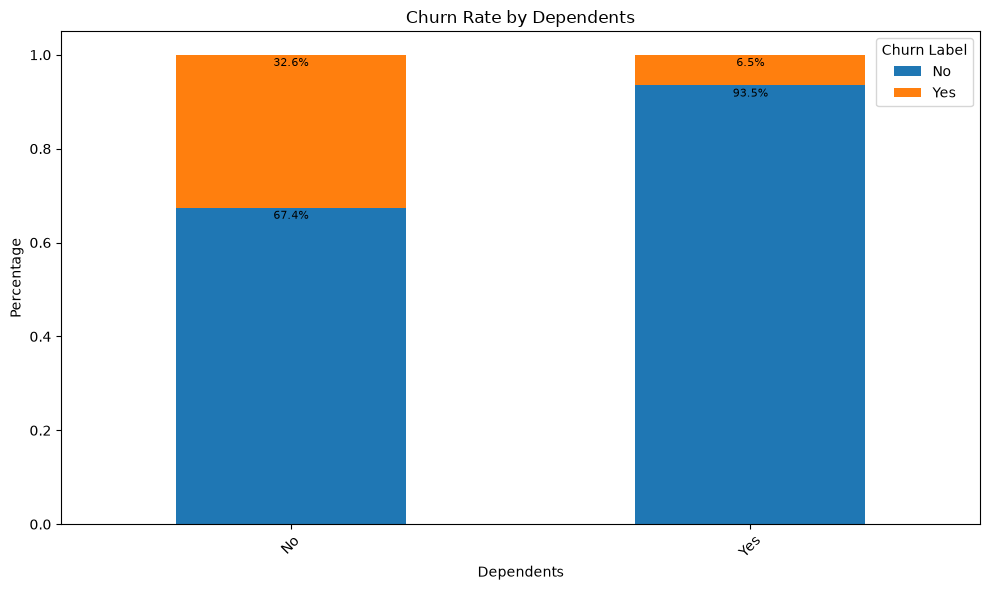

In [55]:
# Stacked percentage bar chart of churn label by Dependents

dependents_churn_counts = df.groupby(['Dependents', 'Churn Label']).size().unstack(fill_value=0)
dependents_churn_percentage = dependents_churn_counts.div(dependents_churn_counts.sum(axis=1), axis=0)

ax = dependents_churn_percentage.plot(kind='bar', stacked=True, figsize=(10, 6))
for container in ax.containers:
    labels = [f'{(value * 100):.1f}%' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=-10, fontsize=8)

ax.set_title('Churn Rate by Dependents')
ax.set_xlabel('Dependents')
ax.set_ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Business Interpretation**
Customers without dependents show a much higher churn rate at about 32.6%, compared with only 6.5% for customers who have dependents. This suggests that family-related stability may be associated with stronger customer retention.

## Section 6: Correlation Analysis

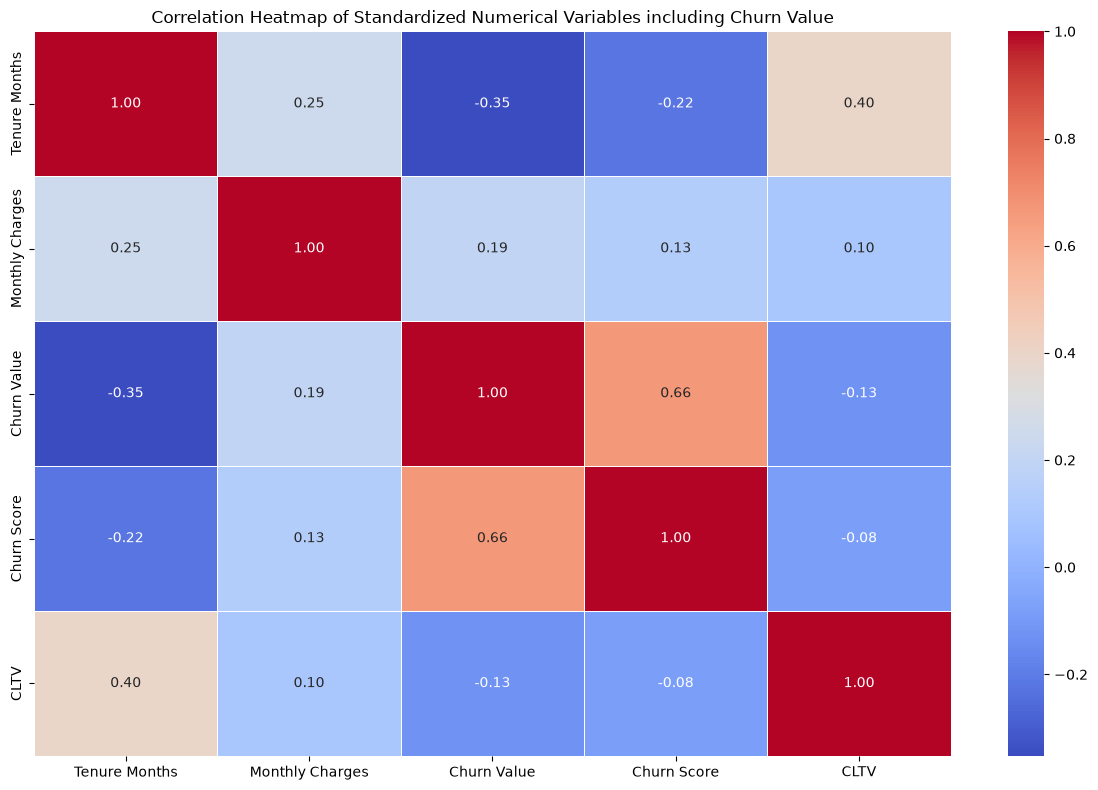

In [61]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Create a numeric churn target for correlation analysis
df['Churn Value'] = df['Churn Label'].map({'Yes': 1, 'No': 0})

# Select numerical variables, excluding the unwanted columns
exclude_columns = ['Zip Code', 'Latitude', 'Longitude', 'Count']
numeric_df = df.select_dtypes(include=['number']).drop(columns=exclude_columns, errors='ignore')

# Standardize the remaining numerical variables before correlation
scaler = StandardScaler()
scaled_numeric_df = pd.DataFrame(
    scaler.fit_transform(numeric_df),
    columns=numeric_df.columns,
    index=numeric_df.index,
)

correlation_matrix = scaled_numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Standardized Numerical Variables including Churn Value')
plt.tight_layout()
plt.show()

In [63]:
import numpy as np
from scipy.stats import chi2_contingency

# Prepare a binary churn target
if 'Churn Value' not in df.columns:
    df['Churn Value'] = df['Churn Label'].map({'Yes': 1, 'No': 0})

# Categorical variables to test against churn
categorical_columns = [
    'Contract',
    'Internet Service',
    'Payment Method',
    'Online Security',
    'Tech Support',
    'Paperless Billing',
    'Senior Citizen',
    'Dependents',
]

results = []
for col in categorical_columns:
    contingency_table = pd.crosstab(df[col], df['Churn Label'])
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    # Cramer's V
    n = contingency_table.sum().sum()
    cramer_v = np.sqrt(chi2 / (n * min(contingency_table.shape[0] - 1, contingency_table.shape[1] - 1)))

    results.append({
        'Variable': col,
        'Chi-Square': chi2,
        'p-value': p_value,
        'Cramers V': cramer_v,
        'Significant': p_value < 0.05,
    })

summary_df = pd.DataFrame(results).sort_values(by='p-value')
summary_df


,Variable,Chi-Square,p-value,Cramers V,Significant
0,Contract,1184.596572,5.863038e-258,0.410116,True
3,Online Security,849.998968,2.661150e-185,0.347400,True
4,Tech Support,828.197068,1.443084e-180,0.342916,True
1,Internet Service,732.309590,9.571788e-160,0.322455,True
2,Payment Method,648.142327,3.682355e-140,0.303359,True
7,Dependents,433.734379,2.500972e-96,0.248161,True
5,Paperless Billing,258.277649,4.073355e-58,0.191498,True
6,Senior Citizen,159.426300,1.510067e-36,0.150453,True


In [64]:
# Show only statistically significant associations
significant_results = summary_df[summary_df['Significant']].copy()
significant_results['p-value'] = significant_results['p-value'].round(6)
significant_results['Chi-Square'] = significant_results['Chi-Square'].round(3)
significant_results['Cramers V'] = significant_results['Cramers V'].round(3)

significant_results[['Variable', 'Chi-Square', 'p-value', 'Cramers V']].reset_index(drop=True)

,Variable,Chi-Square,p-value,Cramers V
0,Contract,1184.597,0.0,0.410
1,Online Security,849.999,0.0,0.347
2,Tech Support,828.197,0.0,0.343
3,Internet Service,732.310,0.0,0.322
4,Payment Method,648.142,0.0,0.303
5,Dependents,433.734,0.0,0.248
6,Paperless Billing,258.278,0.0,0.191
7,Senior Citizen,159.426,0.0,0.150


## Section 8: Geographical Analysis

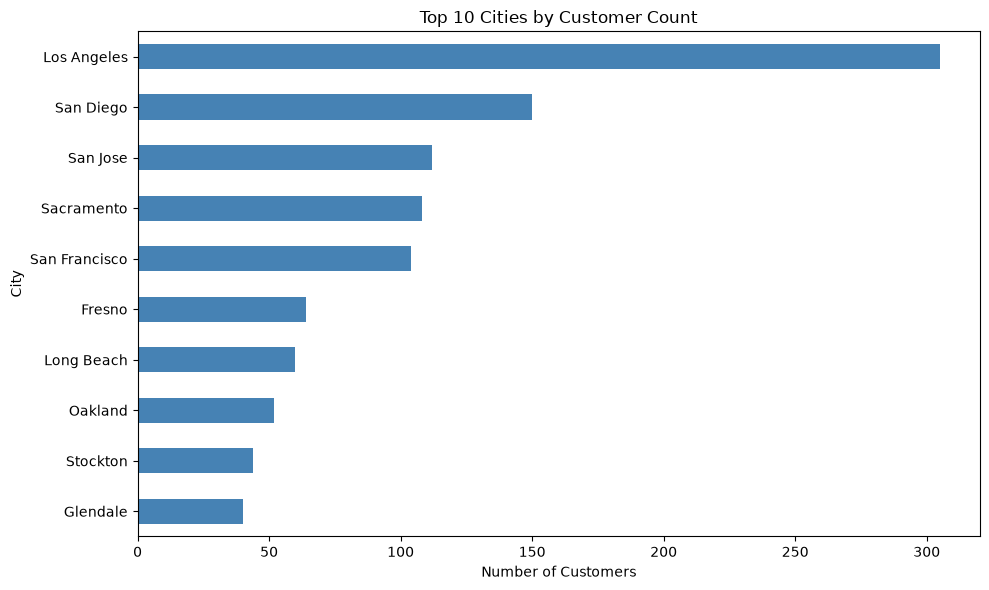

In [69]:

# City-level customer distribution
city_counts = df['City'].value_counts().head(10)

plt.figure(figsize=(10, 6))
city_counts.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 10 Cities by Customer Count')
plt.xlabel('Number of Customers')
plt.ylabel('City')
plt.tight_layout()
plt.show()

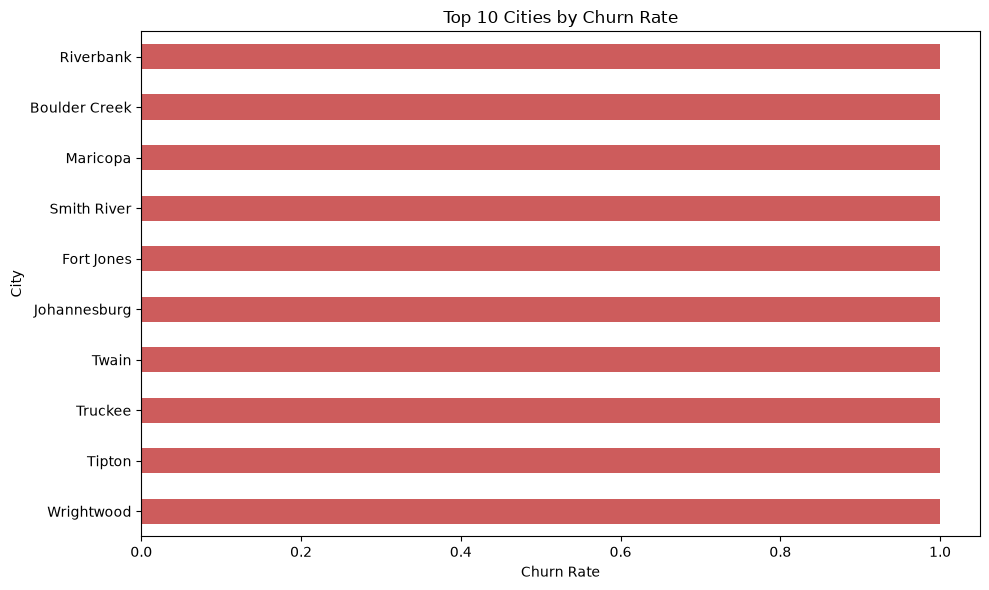

In [70]:
# City-level churn rate
city_churn = (
    df.groupby('City')['Churn Label']
      .apply(lambda s: (s == 'Yes').mean())
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))
city_churn.sort_values().plot(kind='barh', color='indianred')
plt.title('Top 10 Cities by Churn Rate')
plt.xlabel('Churn Rate')
plt.ylabel('City')
plt.tight_layout()
plt.show()



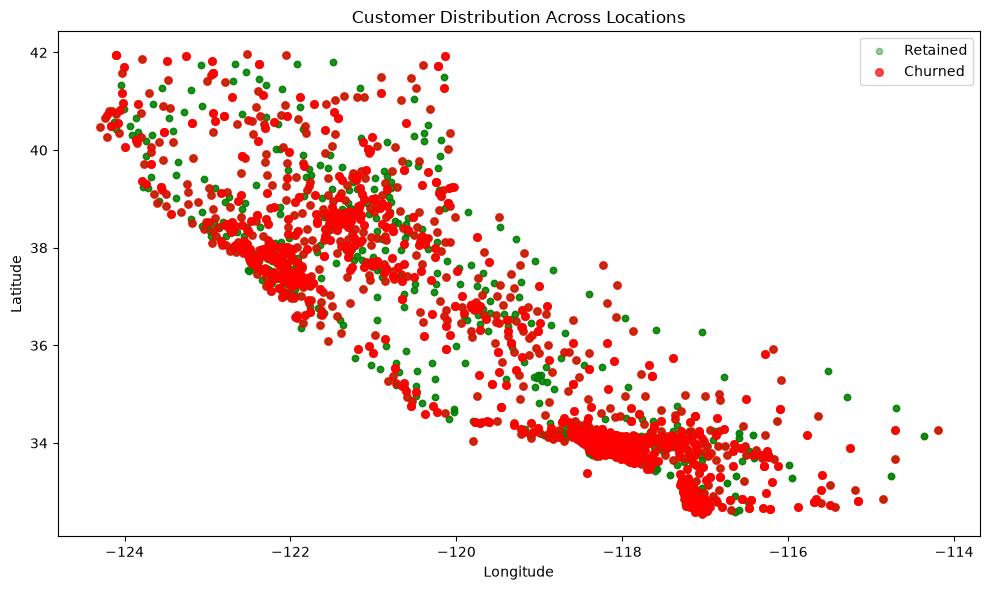

In [71]:
# Location distribution using latitude and longitude
plt.figure(figsize=(10, 6))

# Plot retained customers in green and churned customers in red
retained = df[df['Churn Label'] == 'No']
churned = df[df['Churn Label'] == 'Yes']

plt.scatter(retained['Longitude'], retained['Latitude'], alpha=0.4, s=20, color='green', label='Retained')
plt.scatter(churned['Longitude'], churned['Latitude'], alpha=0.7, s=30, color='red', label='Churned')

plt.title('Customer Distribution Across Locations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.tight_layout()
plt.show()

**Business Interpretation of Correlation and Geographical Analysis**

The analysis shows that churn is not random: customers with shorter contracts, higher service costs, weaker support or security features, and certain payment or demographic profiles are more likely to leave. 

The statistical tests confirm that many of these categorical factors are strongly associated with churn, while the location analysis suggests that churn is also concentrated in particular cities and geographic clusters. 

These findings point to clear retention opportunities around contract design, service experience, customer support, and targeted interventions for high-risk segments.

## Section 10: Overall Business Insight

| Observation from analysis | Business implication |
|---|---|
| Customers with shorter contracts churn more often | Offer longer-term plans and retention incentives to reduce attrition. |
| Higher monthly charges are linked to churn | Review pricing, packaging, and value messaging for cost-sensitive customers. |
| Customers without strong support or security features churn more | Improve service quality, support responsiveness, and digital protection features. |
| Certain payment methods show higher churn | Simplify billing and promote more convenient payment options. |
| Churn is concentrated in some cities or locations | Prioritize local retention campaigns and region-specific service improvements. |
| Customers with dependents and longer relationships are more stable | Use these traits to identify lower-risk segments and focus proactive retention on higher-risk customers. |

## Section 11: EDA Summary

The EDA highlights several variables strongly associated with churn, especially contract type, monthly charges, tenure, churn score, internet service, online security, tech support, payment method, paperless billing, senior citizen status, and dependents. These variables should be retained for modeling because they show clear differences between churners and non-churners. Variables such as City, Zip Code, Latitude, Longitude, and Count appear less useful for direct predictive modeling and may be considered for removal or feature engineering, depending on whether location-based patterns are needed. These findings will inform preprocessing, feature engineering, and model development in subsequent stages.